***Few-shot learning***

Few-shot learning is a classification framework from a very small amount of training data.

The problem of few-shot learning is formulated as learning a representation of the support and query sets, called support and query vectors.

- **support set**: a small group of labeled examples to teach the model a new class 
- **query set**: unseen data samples that the model must clussify or predict using the support set.

Few-shot classification is a task in which a classifier must be adapted to acommodate **new classes not seen in training**, given only a **few examples** of each of these classes.

![Matching networks vs. Prototypical networks](./FSL.png)

In [1]:
import Pkg;

In [2]:
using Random
using Statistics
using LinearAlgebra
using Plots
using StatsBase

Random.seed!(42)

TaskLocalRNG()

What is prototypization?

- representing a group of examples using a representative object, called a prototype

ex: for numerical data: a simple prototype is the mean of the examples belonging to a class.

As you increase the number of support examples, **the prototype summarizes more information about the class**, while K-NN continues to use individual examples.

In [ ]:
# Generate random points around a class center
function generate_class(rng, center, n, σ, dimension)
        return randn(rng, n, dimension) .* σ .+ center'
end


function generate_datapoints_around_center(centers, dimension;σ=1.0)
    # Generate 50 examples for each class
    num_of_datapoints_per_class = 50
    rng = MersenneTwister(42)

    num_of_classes = size(centers)[1]
    
    data = [
        generate_class(rng, centers[k, :], num_of_datapoints_per_class, σ, dimension)
        for k in 1:num_of_classes
    ]
    return data
end


generate_datapoints_around_center (generic function with 1 method)

In [6]:
# Three class centers
dimension = 2
centers_d_2 = [
    0.0  0.0
    4.0  0.0
    2.0  3.0
]

data_d_2 = generate_datapoints_around_center(centers_d_2, dimension, σ=0.9)

3-element Vector{Matrix{Float64}}:
 [1.0892538198441333 1.757447950945908; -0.07109874394972589 -0.5282714472769886; … ; 1.31067489625061 0.5568130254133435; 0.22821607498008323 -0.7622561561799582]
 [3.9090953702633757 -1.0877937992552065; 4.051852849607862 0.05290685958766714; … ; 4.111546608441103 0.032257067359650886; 3.6996874262719395 -0.9195120111101281]
 [2.4839503344802676 2.756141436277393; 0.7112175443575712 3.8057284363170067; … ; 1.365458452011228 2.8926611894283285; 1.7689515347338542 3.2531616942835733]

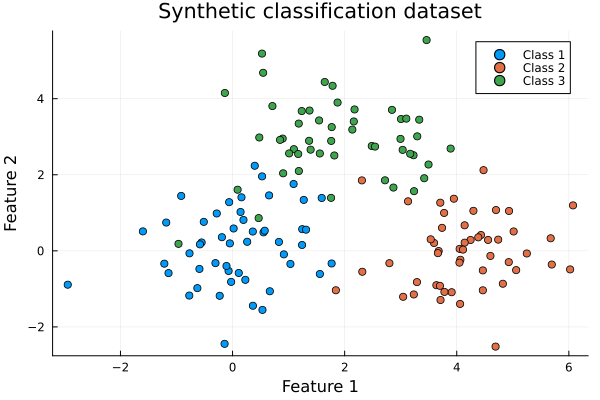

In [7]:

# Visualize the datapoints
p = scatter(
    data_d_2[1][:, 1], data_d_2[1][:, 2],
    label="Class 1",
    xlabel="Feature 1",
    ylabel="Feature 2",
    title="Synthetic classification dataset"
)

scatter!(p, data_d_2[2][:, 1], data_d_2[2][:, 2], label="Class 2")
scatter!(p, data_d_2[3][:, 1], data_d_2[3][:, 2], label="Class 3")

display(p)

Get the prototype of each class simulating having 5 support data/class and 45 query data/class

In [14]:
# Compute one prototype per class
function compute_prototypes(support, labels)
    classes = sort(unique(labels))

    prototypes = [
        vec(mean(support[labels .== k, :], dims=1)) # Get the mean of the support vectors which label is k
        for k in classes
    ]

    return reduce(vcat, [p' for p in prototypes])
end

# Predict the class of a single point
function predict_prototype(x, prototypes)
    distances = [
        sum((x .- prototypes[k, :]).^2)
        for k in 1:size(prototypes, 1)
    ]

    return argmin(distances)
end

predict_prototype (generic function with 1 method)

In [16]:
nshot = 5

# The first nshot will be the support data
support = vcat([
    data_d_2[k][1:nshot, :]
    for k in 1:3
]...)

len_data = size(data_d_2[1], 1)

# This generates a vector having nshot items 1, then nshot items 2 ....
support_labels = repeat(1:3, inner=nshot)


# Remaining examples are queries
query = vcat([
    data_d_2[k][(nshot + 1):end, :]
    for k in 1:3
]...)

query_labels = repeat(1:3, inner=len_data-nshot)

# Calculate the prototypes
prototypes = compute_prototypes(support, support_labels)

# Classify the query points
predictions = [
    predict_prototype(query[i, :], prototypes)
    for i in 1:size(query, 1)
]

accuracy = mean(predictions .== query_labels)

println("Accuracy: ", round(100 * accuracy, digits=2), "%")
println("Prototypes:")
display(prototypes)

Accuracy: 92.59%
Prototypes:


3×2 Matrix{Float64}:
 0.316387  0.260776
 4.33919   0.0264561
 1.31115   3.1747

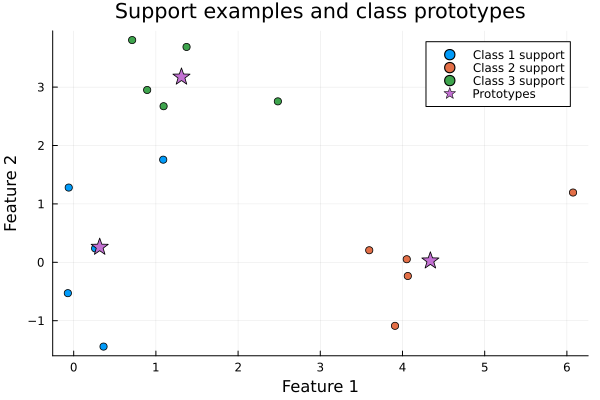

In [34]:
p = scatter(
    support[support_labels .== 1, 1], # the first feature of support data, if its label = 1
    support[support_labels .== 1, 2], # the second feature of support data, if its label = 1
    label="Class 1 support",
    xlabel="Feature 1",
    ylabel="Feature 2",
    title="Support examples and class prototypes"
)

scatter!(
    p,
    support[support_labels .== 2, 1],
    support[support_labels .== 2, 2],
    label="Class 2 support"
)

scatter!(
    p,
    support[support_labels .== 3, 1],
    support[support_labels .== 3, 2],
    label="Class 3 support"
)

scatter!(
    p,
    prototypes[:, 1],
    prototypes[:, 2],
    label="Prototypes",
    markersize=9,
    markershape=:star5
)

display(p)

In [11]:
shot_values = [1, 2, 5, 10]

4-element Vector{Int64}:
  1
  2
  5
 10

In [35]:
function euc_dist(point_1, point_2)
    return sqrt(sum((point_1 .- point_2).^2))
end

# Classify a point using its nearest individual support example
function predict_knn(k, x, support, labels)
    distances = [
        euc_dist(x, support[i, :])
        for i in 1:size(support, 1)
    ]
    
    # Sort distances 
    sorted_indices_of_distances = sortperm(distances)
    
    # Get the labels of K nearest items
    k_nearest_labels = [labels[i] for i in sorted_indices_of_distances[1:k]]

    return findmax(countmap(k_nearest_labels))[2]
end


# Evaluate a method using randomly selected support examples
function evaluate_method(data, nshot; trials=100, method=:prototype, k=1)
    rng = MersenneTwister(1000 + nshot)

    correct = 0
    total = 0

    # [Run more trials, setting support data randomly] -> average accuracy
    for trial in 1:trials
        support_parts = []
        query_parts = []

        support_labels = Int[]
        query_labels = Int[]

        # Select a new support set for each class
        for k in 1:length(data)
            indices = randperm(rng, size(data[k], 1))

            support_idx = indices[1:nshot]
            query_idx = indices[(nshot + 1):end]

            push!(support_parts, data[k][support_idx, :])
            push!(query_parts, data[k][query_idx, :])

            append!(support_labels, fill(k, nshot))
            append!(query_labels, fill(k, length(query_idx)))
        end

        support = vcat(support_parts...)
        query = vcat(query_parts...)

        if method == :prototype
            prototypes = compute_prototypes(support, support_labels)

            predictions = [
                predict_prototype(query[i, :], prototypes)
                for i in 1:size(query, 1)
            ]

        elseif method == :knn
            predictions = [
                predict_knn(k, query[i, :], support, support_labels)
                for i in 1:size(query, 1)
            ]

        else
            error("Unknown method: $method")
        end

        correct += sum(predictions .== query_labels)
        total += length(query_labels)
    end
    return correct / total
end


# Compare different numbers of support examples
function prototype_vs_knn_accuracies(data)
    prototype_accuracy = [
        evaluate_method(data, shot, method=:prototype)
        for shot in shot_values
    ]

    knn_accuracy = [
        evaluate_method(data, shot, method=:knn)
        for shot in shot_values
    ]
    return prototype_accuracy, knn_accuracy
end

function print_results(prototype_accuracy, nn_accuracy)
    for i in eachindex(shot_values)
        println(
            "$(shot_values[i])-shot | " *
            "Prototype: $(round(100 * prototype_accuracy[i], digits=2))% | " *
            "1-NN: $(round(100 * nn_accuracy[i], digits=2))%"
        )
    end
end

print_results (generic function with 1 method)

In [36]:
prototype_accuracies_nshot_d_2, knn_accuracies_nshot_d_2 = prototype_vs_knn_accuracies(data_d_2) 
print_results(prototype_accuracies_nshot_d_2, knn_accuracies_nshot_d_2) 

1-shot | Prototype: 85.76% | 1-NN: 85.76%
2-shot | Prototype: 89.27% | 1-NN: 88.0%
5-shot | Prototype: 92.21% | 1-NN: 89.16%
10-shot | Prototype: 92.96% | 1-NN: 89.62%


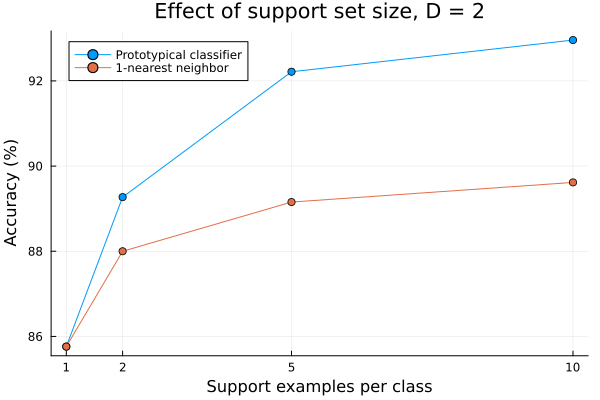

In [37]:
p_2 = plot(
    shot_values,
    100 .* prototype_accuracies_nshot_d_2,
    marker=:circle,
    label="Prototypical classifier",
    xlabel="Support examples per class",
    ylabel="Accuracy (%)",
    title="Effect of support set size, D = 2",
    xticks=shot_values
)

p_2 = plot!(
    p_2,
    shot_values,
    100 .* knn_accuracies_nshot_d_2,
    marker=:circle,
    label="1-nearest neighbor"
)

If data dimension increases above 20:

In [49]:
using Random
using Statistics
using LinearAlgebra
using Plots

dimension = 15

centers_d_15 = [
    0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
    4.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
    2.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
]

data_d_15 = generate_datapoints_around_center(centers_d_15, dimension, σ=0.9)
prototype_accuracies_nshot_d_15, knn_accuracies_nshot_d_15 = prototype_vs_knn_accuracies(data_d_15) 
print_results(prototype_accuracies_nshot_d_15, knn_accuracies_nshot_d_15) 


1-shot | Prototype: 75.54% | 1-NN: 75.54%
2-shot | Prototype: 86.03% | 1-NN: 81.18%
5-shot | Prototype: 92.93% | 1-NN: 85.77%
10-shot | Prototype: 95.15% | 1-NN: 88.42%


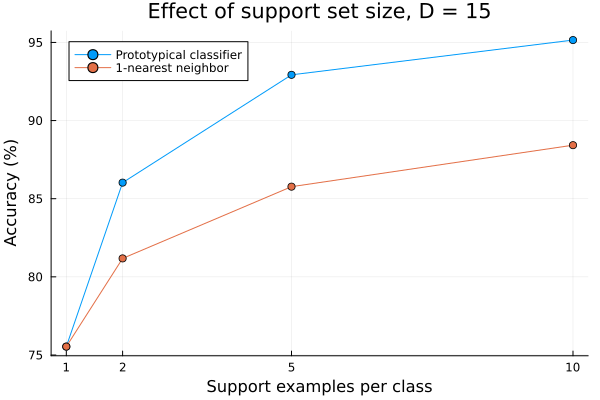

In [47]:
p_15 = plot(
    shot_values,
    100 .* prototype_accuracies_nshot_d_15,
    marker=:circle,
    label="Prototypical classifier",
    xlabel="Support examples per class",
    ylabel="Accuracy (%)",
    title="Effect of support set size, D = 15",
    xticks=shot_values
)

p_15 = plot!(p_15,
    shot_values,
    100 .* knn_accuracies_nshot_d_15,
    marker=:circle,
    label="1-nearest neighbor"
)

In [48]:
using Random
using Statistics
using LinearAlgebra
using Plots

dimension = 25

centers_d_25 = [
    0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
    4.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
    2.0 3.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 
]

data_d_25 = generate_datapoints_around_center(centers_d_25, dimension, σ=0.9)
prototype_accuracies_nshot_d_25, knn_accuracies_nshot_d_25 = prototype_vs_knn_accuracies(data_d_25) 
print_results(prototype_accuracies_nshot_d_25, knn_accuracies_nshot_d_25) 


1-shot | Prototype: 63.8% | 1-NN: 63.8%
2-shot | Prototype: 75.46% | 1-NN: 68.25%
5-shot | Prototype: 83.8% | 1-NN: 73.33%
10-shot | Prototype: 88.21% | 1-NN: 75.97%


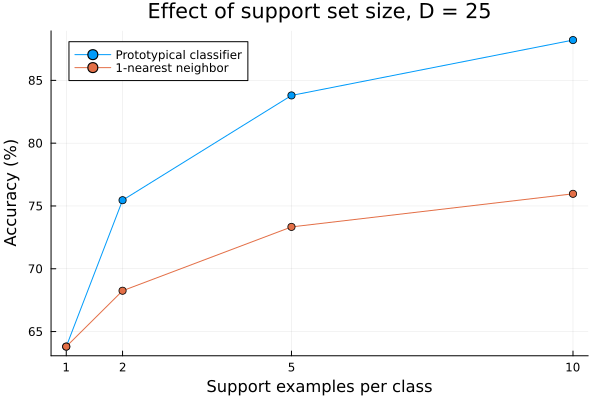

In [117]:
p_25 = plot(
    shot_values,
    100 .* prototype_accuracies_nshot_d_25,
    marker=:circle,
    label="Prototypical classifier",
    xlabel="Support examples per class",
    ylabel="Accuracy (%)",
    title="Effect of support set size, D = 25",
    xticks=shot_values
)

p_25 = plot!(
    p_25,
    shot_values,
    100 .* knn_accuracies_nshot_d_25,
    marker=:circle,
    label="1-nearest neighbor"
)

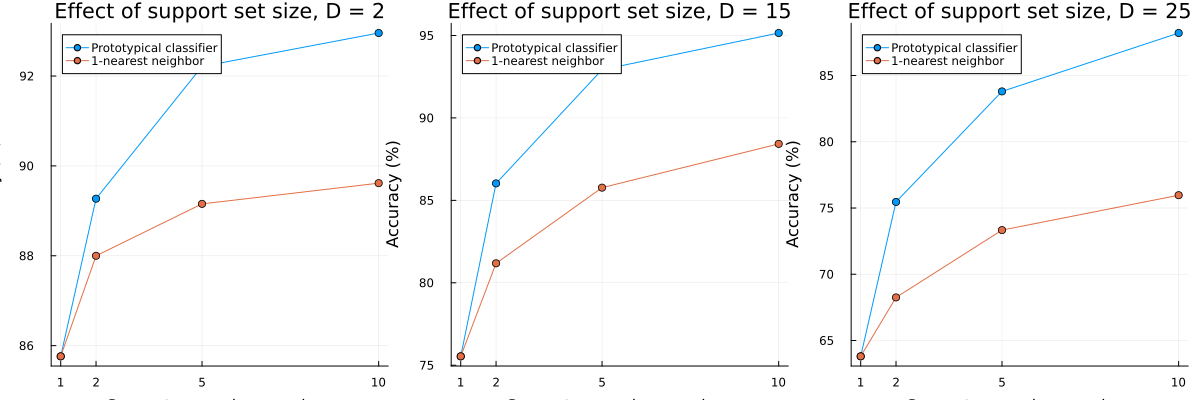

In [118]:
plot(p_2, p_15, p_25, layout=(1, 3), size=(1200, 400))

**Zero-shot learning**: 
- instead of being given a support set of training points, we are given a class meta-data vector vk for each class
- **the model uses pre-existing semantic knowledge**, natural language descriptions, or shared vector spaces to generalize



***Few-shot learning vs. Zero-shot learning***

![Few shot learning vs Zero shot learning](./few_shot_vs_zero_shot_arxiv.png)